# Phase05

March 2025, all Spain, distrito level. External data (INE renta + age, SEPE paro) cleaned in `data/prep_external_data.py`.

## 1. Setup

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
import statsmodels.formula.api as smf
from scipy.stats import spearmanr

DATA = Path("/Users/theocoronges/Documents/internship2026/data")
GEO  = DATA / "geometries"
REC_OD = DATA / "recent_2025-03" / "Viajes_distritos_2025-03_v2.parquet"   # full month, distrito level
K = 10   # number of income groups (deciles) used for the income-mix entropy

## 2. External data → MITMA districts

In [2]:
xw    = pd.read_csv(GEO / "relacion_ine_zonificacionMitma.csv", sep="|", dtype=str)
renta = pd.read_csv(DATA / "renta/renta_seccion_2023.csv", dtype={"seccion_ine": str})
pop   = pd.read_csv(DATA / "demo/pop_seccion_2023.csv",     dtype={"seccion_ine": str})
wa    = pd.read_csv(DATA / "demo/workingage_seccion_2023.csv", dtype={"seccion_ine": str})

sec = (xw[["seccion_ine", "municipio_ine", "distrito_mitma"]]
       .merge(renta, on="seccion_ine", how="left")
       .merge(pop,   on="seccion_ine", how="left")
       .merge(wa,    on="seccion_ine", how="left"))

# population-weighted mean income per MITMA district (weight = section population, only where income exists)
sec["w"]  = np.where(sec["renta_persona"].notna(), sec["poblacion"].fillna(0.0), 0.0)
sec["rw"] = sec["renta_persona"].fillna(0.0) * sec["w"]
g = sec.groupby("distrito_mitma")
D = pd.DataFrame({
    "renta":  g["rw"].sum() / g["w"].sum().replace(0, np.nan),   # €/person/yr
    "pop":    g["poblacion"].sum(),
    "wa_pop": g["working_age_pop"].sum(),                         # 18-64 population
})
print(f"MITMA districts: {len(D):,}   with income: {D['renta'].notna().sum():,}")

MITMA districts: 3,792   with income: 3,741


In [3]:
paro = pd.read_csv(DATA / "paro/paro_municipios_2025-03.csv", dtype={"municipio_ine": str})
# apportion each municipio's unemployed across its sections by WORKING-AGE population, then sum to districts
muni_wa = sec.groupby("municipio_ine")["working_age_pop"].sum().rename("muni_wa")
sm = (sec.merge(paro, on="municipio_ine", how="left")
         .merge(muni_wa, on="municipio_ine", how="left"))
sm["sec_paro"] = sm["total_paro"] * sm["working_age_pop"] / sm["muni_wa"].replace(0, np.nan)
D["paro"] = sm.groupby("distrito_mitma")["sec_paro"].sum()
# registered unemployed per 100 WORKING-AGE (18-64) residents — a proper rate, close to the official one
D["paro_rate"] = 100 * D["paro"] / D["wa_pop"].replace(0, np.nan)
D.loc[~np.isfinite(D["paro_rate"]), "paro_rate"] = np.nan

print(D[["renta", "paro_rate"]].describe().round(2))

          renta  paro_rate
count   3741.00    3742.00
mean   14078.12       8.46
std     2949.41       3.27
min     7265.33       0.00
25%    11931.32       6.25
50%    13710.02       8.00
75%    15683.72      10.30
max    31907.21      41.45


## 3. Income deciles + maps

In [4]:
di = D.dropna(subset=["renta", "pop"])
di = di[(di["renta"] > 0) & (di["pop"] > 0)].sort_values("renta")
cumpop = di["pop"].cumsum() / di["pop"].sum()
D["income_decile"] = np.ceil(cumpop * K).clip(1, K).astype("Int64")

dec_tbl = (D.dropna(subset=["income_decile"])
           .groupby("income_decile")
           .agg(renta_min=("renta", "min"), renta_max=("renta", "max"),
                districts=("renta", "size"), pop=("pop", "sum")))
dec_tbl.round(0)

,renta_min,renta_max,districts,pop
income_decile,,,,
1,7265.0,11169.0,574,4719643.0
2,11169.0,12058.0,418,4540021.0
3,12060.0,12896.0,422,4930138.0
4,12898.0,13529.0,359,4729226.0
5,13533.0,14158.0,388,4732584.0
6,14159.0,15075.0,421,4539774.0
7,15076.0,15976.0,353,4921730.0
8,15980.0,17161.0,328,4730916.0
9,17161.0,19485.0,295,4680981.0


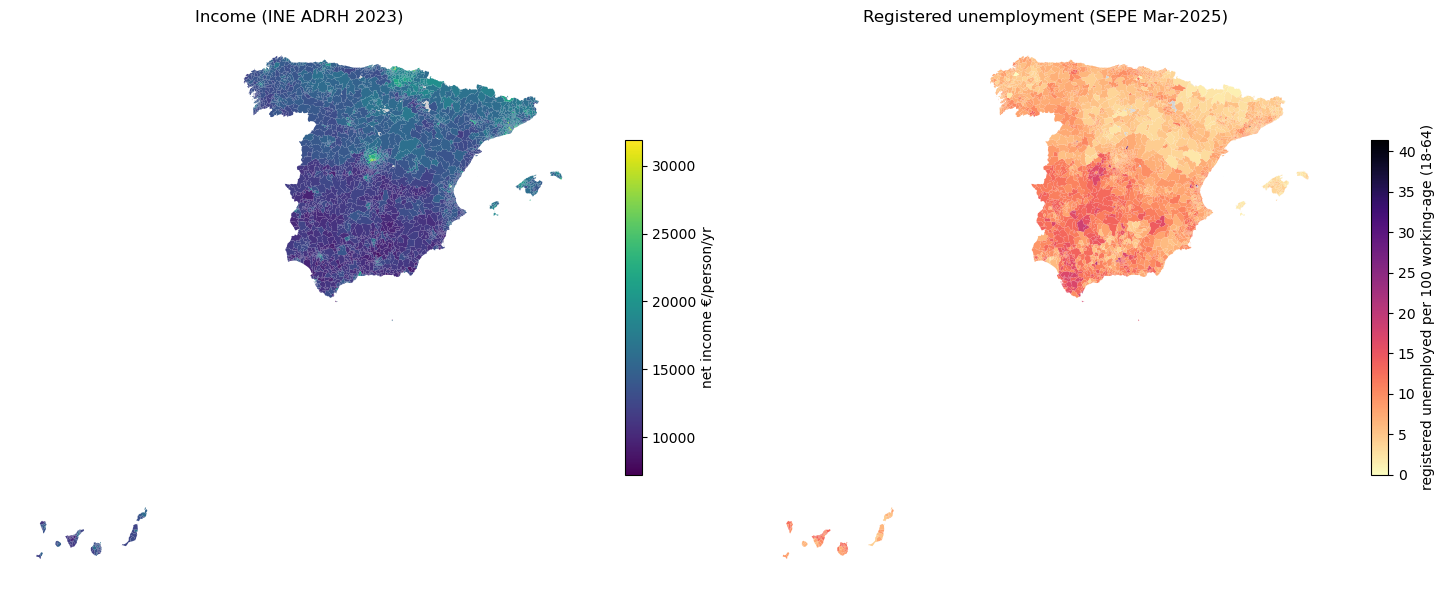

In [5]:
# choropleth: net income per person by district
gdf = gpd.read_file(GEO / "distritos_2.geojson")[["id", "geometry"]]
gdf = gdf.merge(D, left_on="id", right_index=True, how="left")

fig, ax = plt.subplots(1, 2, figsize=(15, 7))
gdf.plot(column="renta", cmap="viridis", legend=True, ax=ax[0],
         legend_kwds={"label": "net income €/person/yr", "shrink": 0.5},
         missing_kwds={"color": "lightgrey"})
ax[0].set_title("Income (INE ADRH 2023)"); ax[0].set_axis_off()
gdf.plot(column="paro_rate", cmap="magma_r", legend=True, ax=ax[1], scheme=None,
         legend_kwds={"label": "registered unemployed per 100 working-age (18-64)", "shrink": 0.5},
         missing_kwds={"color": "lightgrey"})
ax[1].set_title("Registered unemployment (SEPE Mar-2025)"); ax[1].set_axis_off()
plt.tight_layout()

## 4. OD → district pairs (full month)

In [6]:
CACHE = DATA / "recent_2025-03" / "_od_pairs_cache.parquet"
if CACHE.exists():
    pairs = pd.read_parquet(CACHE)
else:
    od = pd.read_parquet(REC_OD, columns=["id_origin", "id_destination", "n_trips"])
    for c in ["id_origin", "id_destination"]:
        od[c] = od[c].astype("category")
    pairs = (od.groupby(["id_origin", "id_destination"], observed=True, as_index=False)["n_trips"].sum())
    pairs["id_origin"] = pairs["id_origin"].astype(str)
    pairs["id_destination"] = pairs["id_destination"].astype(str)
    pairs = pairs[pairs["id_origin"] != pairs["id_destination"]]
    pairs.to_parquet(CACHE)

pairs["o_dec"] = pairs["id_origin"].map(D["income_decile"]).astype("float")
pairs["d_dec"] = pairs["id_destination"].map(D["income_decile"]).astype("float")
print(f"directed cross-district pairs: {len(pairs):,}   total trips: {pairs['n_trips'].sum():,.0f}")

directed cross-district pairs: 3,359,772   total trips: 3,106,215,784


## 5. Experienced income diversity + selectivity

In [7]:
# income-decile mix of the inbound trips of each destination
d = pairs.dropna(subset=["o_dec"]).copy(); d["o_dec"] = d["o_dec"].astype(int)
tab = d.groupby(["id_destination", "o_dec"])["n_trips"].sum().unstack(fill_value=0.0).reindex(columns=range(1, K + 1), fill_value=0.0)
trips_in = tab.sum(axis=1)
P = tab.div(trips_in, axis=0)                       # per-destination income distribution
q = (tab.sum(axis=0) / tab.sum().sum()).values      # national baseline (trip-weighted income mix)

def _safe(a, b):
    with np.errstate(divide="ignore", invalid="ignore"):
        return np.where(a > 0, a * np.log2(a / b), 0.0)

# H_norm: balance of the mix (MITMA/pySpainMobility metric).  JSD: divergence from the national mix (selectivity).
Pv, qv = P.values, q[None, :]
Hn = -(np.where(Pv > 0, Pv * np.log2(np.where(Pv > 0, Pv, 1.0)), 0.0)).sum(axis=1) / np.log2(K)
M = 0.5 * (Pv + qv)
JSD = 0.5 * _safe(Pv, M).sum(axis=1) + 0.5 * _safe(qv, M).sum(axis=1)   # base-2 -> [0,1]

dest = pd.DataFrame({"H_norm": Hn, "JSD": JSD, "trips_in": trips_in.values}, index=P.index)
dest["renta"]     = dest.index.map(D["renta"])
dest["paro_rate"] = dest.index.map(D["paro_rate"])
dest["log_vol"]   = np.log(dest["trips_in"])
dest = dest[dest["renta"].notna()]
print(dest[["H_norm", "JSD", "trips_in", "renta"]].describe().round(3))

         H_norm       JSD      trips_in      renta
count  3740.000  3740.000  3.740000e+03   3740.000
mean      0.643     0.303  8.271179e+05  14077.706
std       0.139     0.116  1.290062e+06   2949.700
min       0.104     0.045  2.521628e+04   7265.329
25%       0.558     0.214  2.047203e+05  11931.155
50%       0.659     0.292  3.922706e+05  13709.818
75%       0.746     0.386  8.837042e+05  15684.144
max       0.952     0.704  2.006954e+07  31907.206


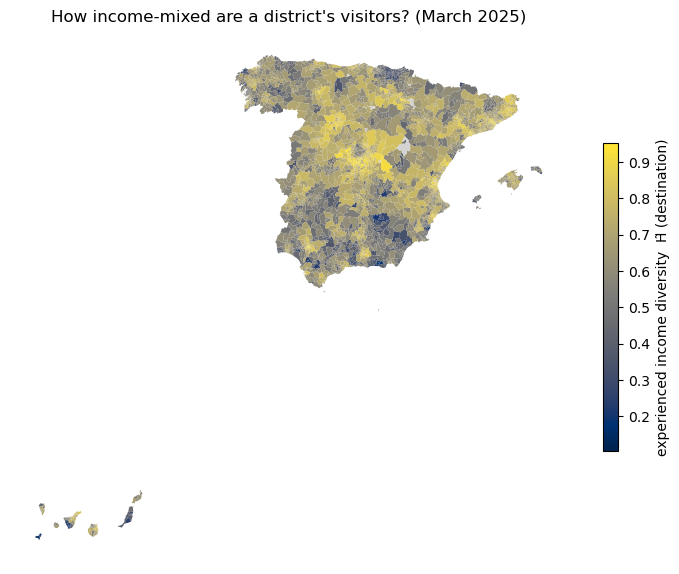

In [8]:
gdf2 = gpd.read_file(GEO / "distritos_2.geojson")[["id", "geometry"]].merge(
    dest["H_norm"], left_on="id", right_index=True, how="left")
fig, ax = plt.subplots(figsize=(9, 8))
gdf2.plot(column="H_norm", cmap="cividis", legend=True, ax=ax,
          legend_kwds={"label": "experienced income diversity  H̃ (destination)", "shrink": 0.5},
          missing_kwds={"color": "lightgrey"})
ax.set_title("How income-mixed are a district's visitors? (March 2025)"); ax.set_axis_off()

## 6. Diversity & selectivity vs income

raw Spearman  H̃ vs income: rho=+0.196  p=9.5e-34  n=3,740


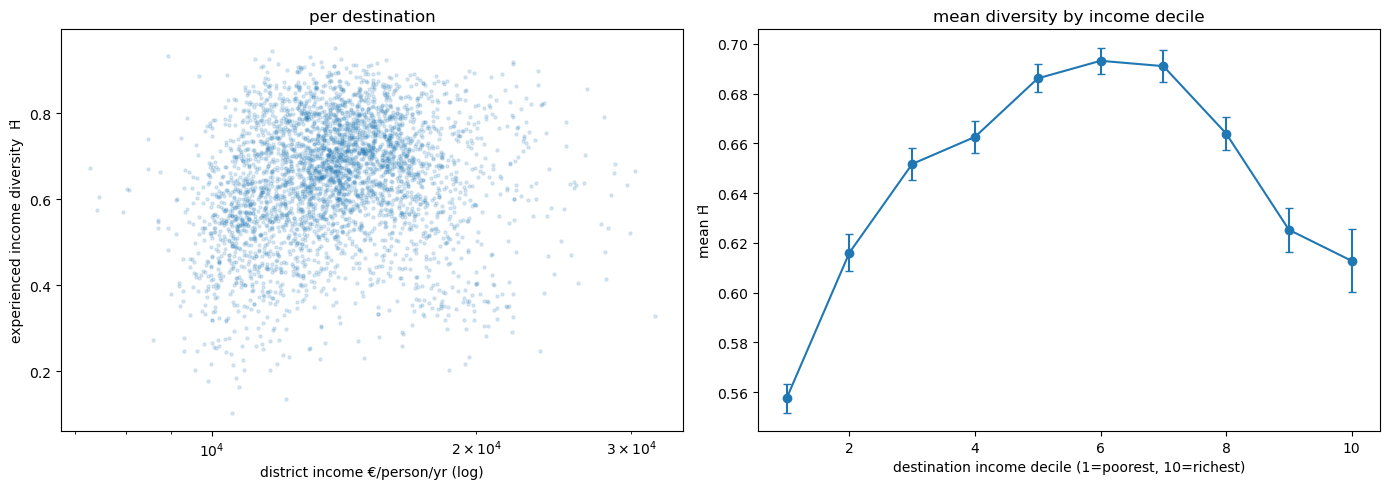

In [9]:
# (a) mean diversity by destination income decile
by_dec = dest.assign(dec=dest.index.map(D["income_decile"])).dropna(subset=["dec"])
prof = by_dec.groupby("dec")["H_norm"].agg(["mean", "sem"])

fig, ax = plt.subplots(1, 2, figsize=(14, 5))
ax[0].scatter(dest["renta"], dest["H_norm"], s=5, alpha=0.15)
ax[0].set_xscale("log"); ax[0].set_xlabel("district income €/person/yr (log)")
ax[0].set_ylabel("experienced income diversity  H̃"); ax[0].set_title("per destination")
ax[1].errorbar(prof.index, prof["mean"], yerr=prof["sem"], marker="o", capsize=3)
ax[1].set_xlabel("destination income decile (1=poorest, 10=richest)")
ax[1].set_ylabel("mean H̃"); ax[1].set_title("mean diversity by income decile")
plt.tight_layout()

rho, p = spearmanr(dest["renta"], dest["H_norm"])
print(f"raw Spearman  H̃ vs income: rho={rho:+.3f}  p={p:.1e}  n={len(dest):,}")

In [10]:
# income relation for both measures: raw rank-corr + coefficient after controlling for trip volume
rows = []
for meas in ["H_norm", "JSD"]:
    rho, _ = spearmanr(dest["renta"], dest[meas])
    m = smf.ols(f"{meas} ~ log_vol + np.log(renta)", data=dest).fit()
    rows.append({"measure": meas, "raw_rho": round(rho, 3),
                 "beta_log_income": round(m.params["np.log(renta)"], 4),
                 "p_income": f"{m.pvalues['np.log(renta)']:.1e}"})
income_rel = pd.DataFrame(rows).set_index("measure")
print(income_rel)

         raw_rho  beta_log_income p_income
measure                                   
H_norm     0.196           0.0656  4.7e-08
JSD       -0.372          -0.1685  8.1e-68


## 7. Income assortativity of flows

In [11]:
# centroid per district (for trip distance)
cent = gpd.read_file(GEO / "distritos_2.geojson")[["id", "geometry"]].set_index("id").geometry.centroid
lon, lat = cent.x, cent.y
EARTH = 6371.0088
def haversine(o, d):
    la1, lo1, la2, lo2 = map(np.radians, (lat.reindex(o).values, lon.reindex(o).values,
                                          lat.reindex(d).values, lon.reindex(d).values))
    a = np.sin((la2 - la1) / 2)**2 + np.cos(la1) * np.cos(la2) * np.sin((lo2 - lo1) / 2)**2
    return 2 * EARTH * np.arcsin(np.sqrt(a))

af = pairs.copy()
af["Ri"] = af["id_origin"].map(D["renta"]); af["Rj"] = af["id_destination"].map(D["renta"])
af["dij"] = haversine(af["id_origin"].values, af["id_destination"].values)
af = af.dropna(subset=["Ri", "Rj", "dij"])

def wcorr(x, y, w):
    w = w / w.sum(); mx, my = (w * x).sum(), (w * y).sum()
    return (w * (x - mx) * (y - my)).sum() / np.sqrt((w * (x - mx)**2).sum() * (w * (y - my)**2).sum())

bins = [0, 25, 100, 300, np.inf]; labs = ["<25 km", "25-100", "100-300", ">300 km"]
af["band"] = pd.cut(af["dij"], bins=bins, labels=labs)
rows = [{"distance": "ALL", "r": wcorr(af["Ri"].values, af["Rj"].values, af["n_trips"].values),
         "trip_share_%": 100.0}]
for b, s in af.groupby("band", observed=True):
    rows.append({"distance": b, "r": wcorr(s["Ri"].values, s["Rj"].values, s["n_trips"].values),
                 "trip_share_%": 100 * s["n_trips"].sum() / af["n_trips"].sum()})
assort = pd.DataFrame(rows).set_index("distance").round({"r": 3, "trip_share_%": 1})
print(assort)

/var/folders/0w/yh4tfdn54cvfyvz1hbf3fn5c0000gn/T/ipykernel_54752/3706838084.py:2: UserWarning: Geometry is in a geographic CRS. Results from 'centroid' are likely incorrect. Use 'GeoSeries.to_crs()' to re-project geometries to a projected CRS before this operation.

  cent = gpd.read_file(GEO / "distritos_2.geojson")[["id", "geometry"]].set_index("id").geometry.centroid


              r  trip_share_%
distance                     
ALL       0.474         100.0
<25 km    0.493          90.3
25-100    0.269           8.5
100-300   0.092           0.9
>300 km   0.037           0.3


trip-weighted slope dRj/dRi = +0.474  (p=0.0e+00)


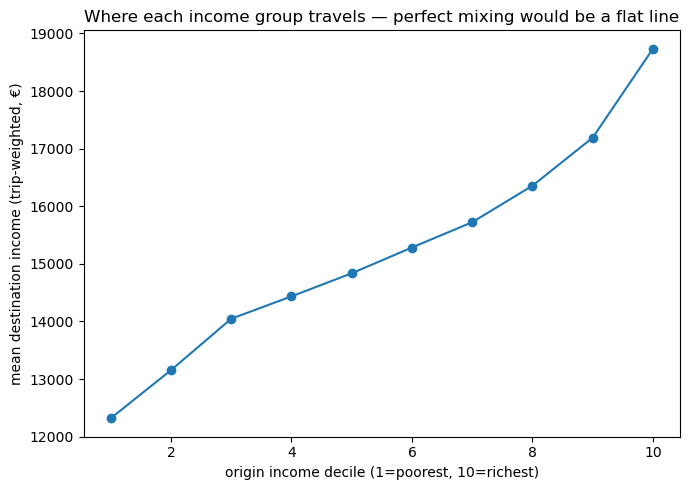

In [12]:
# trip-weighted slope (assortativity as one coefficient) + a decile view
slope = smf.wls("Rj ~ Ri", data=af, weights=af["n_trips"]).fit()
print(f"trip-weighted slope dRj/dRi = {slope.params['Ri']:+.3f}  (p={slope.pvalues['Ri']:.1e})")

afd = af.dropna(subset=["o_dec"]).copy()
afd["o_dec"] = afd["o_dec"].astype(int)
num = (afd.assign(rw=afd["Rj"] * afd["n_trips"])
          .groupby("o_dec").agg(rw=("rw", "sum"), w=("n_trips", "sum")))
prof = num["rw"] / num["w"]
fig, ax = plt.subplots(figsize=(7, 5))
ax.plot(prof.index.astype(int), prof.values, marker="o")
ax.set_xlabel("origin income decile (1=poorest, 10=richest)")
ax.set_ylabel("mean destination income (trip-weighted, €)")
ax.set_title("Where each income group travels — perfect mixing would be a flat line")
plt.tight_layout()

## 8. Mobility-flux diversity vs unemployment

In [13]:
tot = pairs.groupby("id_origin")["n_trips"].sum()
pp  = pairs.assign(q=pairs["n_trips"] / pairs["id_origin"].map(tot))
flux = pp.groupby("id_origin").agg(
    n_dest=("id_destination", "nunique"),
    H_dest=("q", lambda s: -(s * np.log(s)).sum()))
flux["even"]      = flux["H_dest"] / np.log(flux["n_dest"].clip(lower=2))   # size-free evenness
flux["renta"]     = flux.index.map(D["renta"])
flux["paro_rate"] = flux.index.map(D["paro_rate"])
flux = flux[flux["renta"].notna() & flux["paro_rate"].notna()]

print("Spearman correlations (n = %d districts)" % len(flux))
for col in ["H_dest", "even", "n_dest"]:
    r_p = spearmanr(flux["paro_rate"], flux[col])[0]
    r_r = spearmanr(flux["renta"], flux[col])[0]
    print(f"  {col:7s}  vs unemployment: rho={r_p:+.3f}   vs income: rho={r_r:+.3f}")

Spearman correlations (n = 3740 districts)
  H_dest   vs unemployment: rho=-0.148   vs income: rho=+0.168
  even     vs unemployment: rho=-0.146   vs income: rho=+0.060
  n_dest   vs unemployment: rho=-0.000   vs income: rho=+0.267


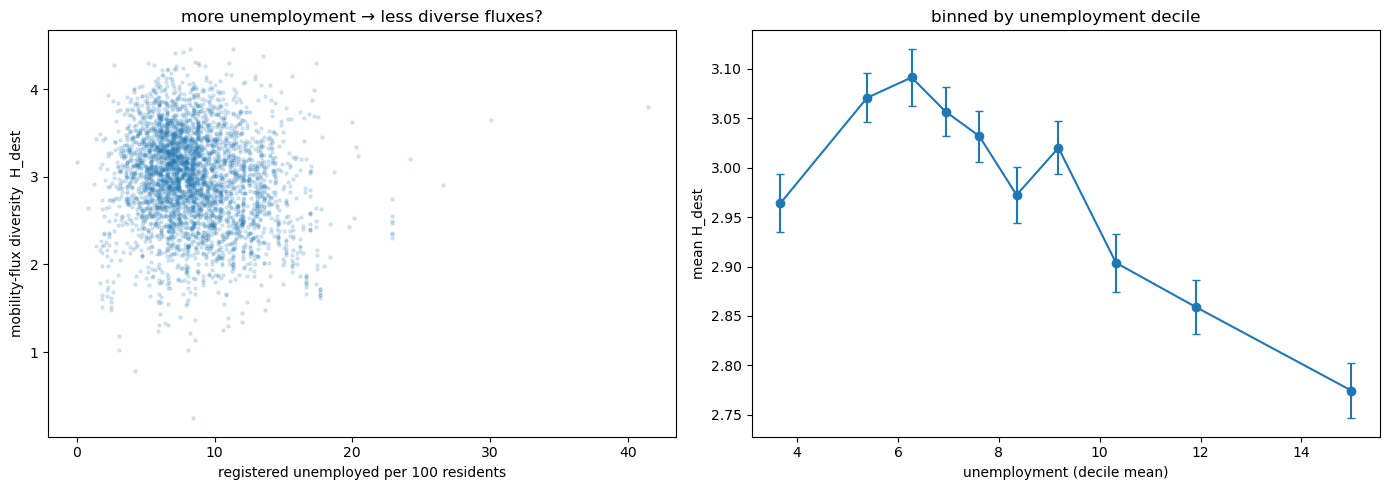

In [14]:
fig, ax = plt.subplots(1, 2, figsize=(14, 5))
ax[0].scatter(flux["paro_rate"], flux["H_dest"], s=5, alpha=0.15)
ax[0].set_xlabel("registered unemployed per 100 residents")
ax[0].set_ylabel("mobility-flux diversity  H_dest"); ax[0].set_title("more unemployment → less diverse fluxes?")
# binned means (deciles of unemployment)
q = pd.qcut(flux["paro_rate"], 10, duplicates="drop")
b = flux.groupby(q, observed=True)["H_dest"].agg(["mean", "sem"])
xm = flux.groupby(q, observed=True)["paro_rate"].mean()
ax[1].errorbar(xm, b["mean"], yerr=b["sem"], marker="o", capsize=3)
ax[1].set_xlabel("unemployment (decile mean)"); ax[1].set_ylabel("mean H_dest")
ax[1].set_title("binned by unemployment decile")
plt.tight_layout()

## 9. Consolidated model

In [15]:
reg = flux.join(dest["H_norm"].rename("H_income"), how="left")
reg = reg.replace([np.inf, -np.inf], np.nan).dropna(subset=["paro_rate", "renta", "H_dest", "even"])
z = lambda s: (s - s.mean()) / s.std()
reg["z_income"] = z(np.log(reg["renta"]))
reg["z_flux"]   = z(reg["H_dest"])
reg["z_even"]   = z(reg["even"])
mm = smf.ols("paro_rate ~ z_income + z_even", data=reg).fit()
print(mm.summary().tables[1])
print(f"\nR^2 = {mm.rsquared:.3f}  (n={int(mm.nobs)})")

                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept      8.4624      0.048    174.824      0.000       8.368       8.557
z_income      -1.3304      0.048    -27.434      0.000      -1.425      -1.235
z_even        -0.3409      0.048     -7.030      0.000      -0.436      -0.246

R^2 = 0.181  (n=3740)


## 10. Findings

1. Higher-income destinations are less segregated — visitor mix is more balanced (entropy) and closer to the
   national mix (JSD, the stronger signal, ρ≈−0.37); poorer/peripheral places are the selective ones.
2. Mobility is income-assortative but only locally (r≈0.47 overall; ~0.49 <25 km; ~0 long-distance).
3. Evener mobility fluxes ↔ lower working-age unemployment, independent of income.